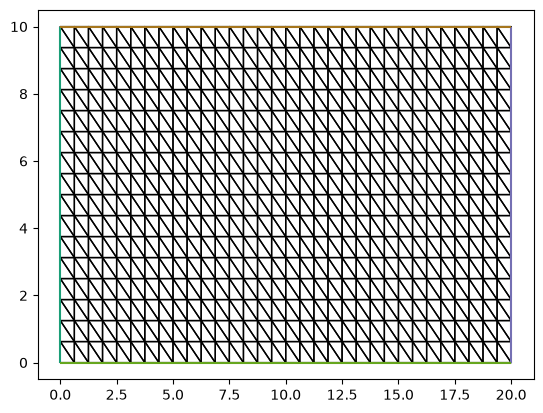

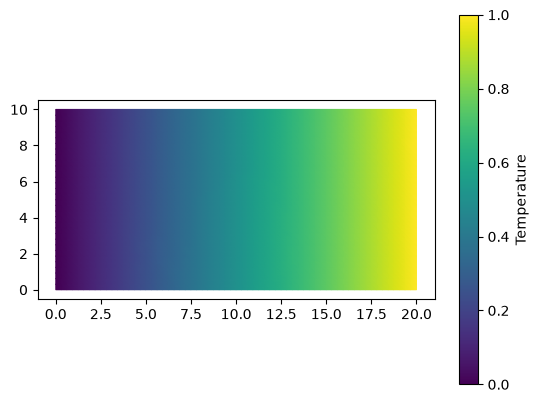

Simulation completed successfully ✅


In [3]:
##################################
#  Steady-state heat conduction  #
##################################

# Import Firedrake
from firedrake import *

# Import matplotlib
import matplotlib.pyplot as plt

## Input parameters
# Material and Geometric properties
D = Constant(1.0)  # Thermal conductivity (isotropic)
L_1 = 20.0         # Length in x-direction
L_2 = 10.0         # Length in y-direction

# Mesh (2D rectangle)
mesh = RectangleMesh(nx=32, ny=16, Lx=L_1, Ly=L_2)
# show the mesh
fig, axes = plt.subplots()
triplot(mesh, axes=axes)
plt.show()


## FE settings
# Function space (P1 Lagrange elements)
V = FunctionSpace(mesh, "CG", 1)  # Continuous Galerkin (linear elements)

# Trial and Test functions
T   = TrialFunction(V)  # Unknown temperature field
eta = TestFunction(V) 


## Boundary conditions
# Neumann boundary condition
q_bar = Constant(0.0)
# Dirichlet boundary conditions
Tbar1 = Constant(0.0)  # Temperature at left 
Tbar2 = Constant(1.0)  # Temperature at right
bcs = [DirichletBC(V, Tbar1, 1), DirichletBC(V, Tbar2, 2)]


## Weak Form
a = inner(grad(eta), D * grad(T)) * dx  # bilinear form 
L = -eta * q_bar * ds                   # linear form


## Solve the problem
# Function to Store the solution
T_h = Function(V, name="T")

# Solve the problem and store the result
solve(a == L, T_h, bcs)


from firedrake.pyplot import tripcolor

fig, ax = plt.subplots()
colours = tripcolor(T_h, axes=ax)
fig.colorbar(colours, ax=ax, label="Temperature")
ax.set_aspect("equal")
plt.show()


# Print completion message
print("Simulation completed successfully \U00002705")

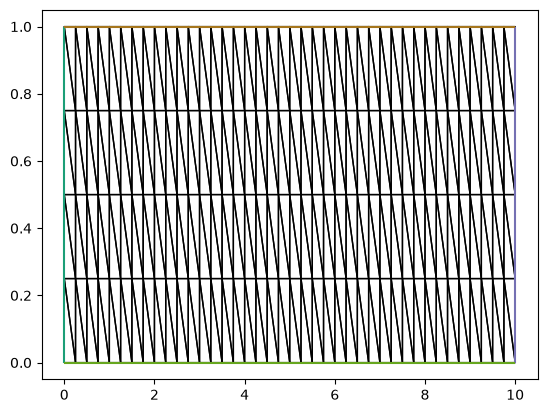

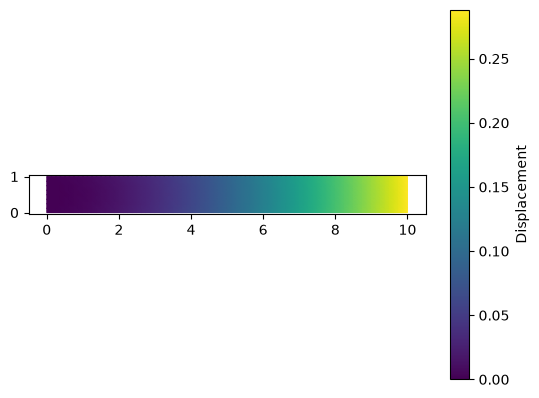

Simulation completed successfully ✅


In [4]:
##################################
#       Linear elasticity        #
##################################

# Import Firedrake
from firedrake import *

# Import matplotlib
import matplotlib.pyplot as plt

## Input parameters
# Material and Geometric properties
E   = Constant(70e9) # Young's modulus
nu  = Constant(0.3)  # Poisson's ratio
L_1 = 10.0           # Length in x-direction
L_2 = 1.0            # Length in y-direction
# 2D assumption 
plane_setting = 2    # 1: Plane strain, 2: Plane stress

# Mesh (2D rectangle)
mesh = RectangleMesh(nx=40, ny=4, Lx=L_1, Ly=L_2)
# show the mesh
fig, axes = plt.subplots()
triplot(mesh, axes=axes)
plt.show()

# Elasticity parameters
lmbda   = E*nu / ((1 + nu)*(1 - 2*nu))  # First Lame parameter
mu      = E / (2*(1 + nu))              # Second Lame parameter (shear modulus)
# Plane stress assumption
if plane_setting == 2:
    alpha = (mu) / (mu + 0.5*lmbda)
    lmbda = alpha * lmbda


## Strain and Stress tensors
def epsilon(u):
    return sym(grad(u))
def sigma(u):
    return lmbda*div(u)*Identity(2) + 2*mu*epsilon(u) 


## FE settings
# Function space (P2 Lagrange elements)
V     = VectorFunctionSpace(mesh, "CG", 2)  # Continuous Galerkin (degree 2)
V_out = VectorFunctionSpace(mesh, "CG", 1)  # Piecewise linear space for output purposes

# Trial and Test functions
u     = TrialFunction(V)  # Displacement field (unknown)
del_u = TestFunction(V)   # Test function (variation of displacement)

## Boundary conditions
# Neumann boundary condition
t_bar = Constant((0.0, -50e5))
nbc1  = 2 # apply traction on the right boundary (2)
# Dirichlet boundary conditions
ubar1 = Constant((0.0, 0.0))  # Displacement at left
# ubar2 = Constant((1.0, 0.0))  # Displacement at right
# bcs = [DirichletBC(V, ubar1, 1), DirichletBC(V, ubar2, 2)]
bcs = [DirichletBC(V, ubar1, 1)]
# Body force
b = Constant((0.0, 0.0))


## Weak Form
a = inner(sigma(del_u), epsilon(u)) * dx                  # bilinear form 
L = inner(b, del_u) * dx + inner(t_bar, del_u) * ds(nbc1) # linear form


## Solve the problem
u_h = Function(V) # Function to Store the solution
solve(a == L, u_h, bcs)

# Write the solution
#outfile = VTKFile("solution.pvd")
#outfile.write(project(u_h, V_out, name="u"))

from firedrake.pyplot import tripcolor

fig, ax = plt.subplots()
colours = tripcolor(u_h, axes=ax)
fig.colorbar(colours, ax=ax, label="Displacement")
ax.set_aspect("equal")
plt.show()

# Print completion message
print("Simulation completed successfully \U00002705")